In [5]:
import numpy as np
import matplotlib.pyplot as plt
import tensorflow as tf

from sklearn.datasets import make_classification
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler


In [6]:

# 1. Create sample tabular data
X, y = make_classification(
    n_samples=1000,
    n_features=10,
    n_informative=6,
    n_redundant=2,
    random_state=42
)


In [7]:

# 2. Split into training and testing data
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42,
    stratify=y
)


In [8]:

# 3. Scale the features
scaler = StandardScaler()
X_train = scaler.fit_transform(X_train)
X_test = scaler.transform(X_test)

# Set random seeds for reproducibility
tf.keras.utils.set_random_seed(42)


In [9]:

# 4. Define a Sequential model
def build_model():
    model = tf.keras.Sequential([
        tf.keras.layers.Input(shape=(X_train.shape[1],)),
        tf.keras.layers.Dense(32, activation="relu"),
        tf.keras.layers.Dense(16, activation="relu"),
        tf.keras.layers.Dense(1, activation="sigmoid")
    ])
    return model


In [10]:

# 5. Build and compile the SGD model
sgd_model = build_model()

sgd_model.compile(
    optimizer=tf.keras.optimizers.SGD(learning_rate=0.01),
    loss="binary_crossentropy",
    metrics=["accuracy"]
)


In [11]:

# 6. Build and compile the Adam model
adam_model = build_model()

adam_model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=0.001),
    loss="binary_crossentropy",
    metrics=["accuracy"]
)


In [12]:

# 7. Train both models
epochs = 30
batch_size = 32

print("Training with SGD...")
sgd_history = sgd_model.fit(
    X_train, y_train,
    validation_split=0.2,
    epochs=epochs,
    batch_size=batch_size,
    verbose=0
)

print("Training with Adam...")
adam_history = adam_model.fit(
    X_train, y_train,
    validation_split=0.2,
    epochs=epochs,
    batch_size=batch_size,
    verbose=0
)


Training with SGD...
Training with Adam...


In [13]:

# 8. Evaluate both models on test data
sgd_loss, sgd_accuracy = sgd_model.evaluate(
    X_test, y_test, verbose=0
)

adam_loss, adam_accuracy = adam_model.evaluate(
    X_test, y_test, verbose=0
)

print("\nTest Results")
print("-" * 40)
print(f"SGD  - Loss: {sgd_loss:.4f}, Accuracy: {sgd_accuracy:.4f}")
print(f"Adam - Loss: {adam_loss:.4f}, Accuracy: {adam_accuracy:.4f}")



Test Results
----------------------------------------
SGD  - Loss: 0.4245, Accuracy: 0.8150
Adam - Loss: 0.2878, Accuracy: 0.8900


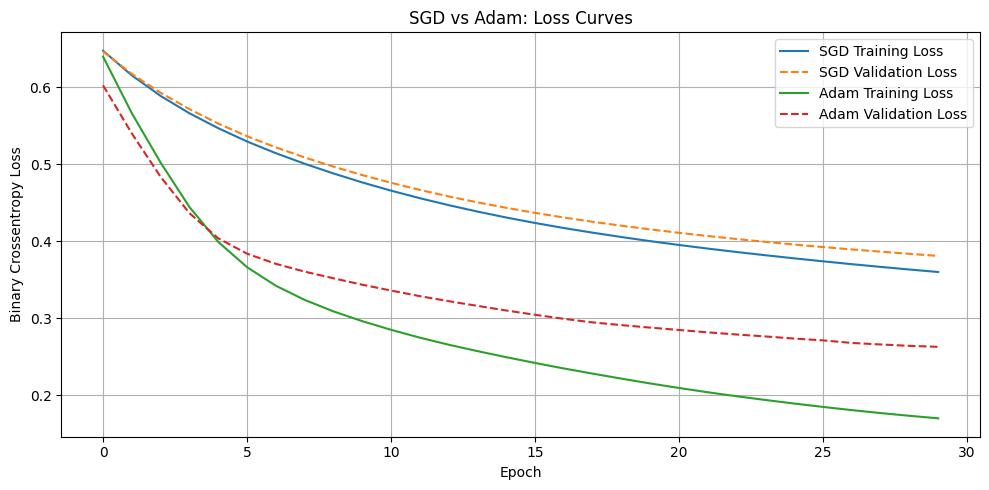

In [14]:

# 9. Plot training and validation loss curves
plt.figure(figsize=(10, 5))

plt.plot(
    sgd_history.history["loss"],
    label="SGD Training Loss"
)
plt.plot(
    sgd_history.history["val_loss"],
    label="SGD Validation Loss",
    linestyle="--"
)
plt.plot(
    adam_history.history["loss"],
    label="Adam Training Loss"
)
plt.plot(
    adam_history.history["val_loss"],
    label="Adam Validation Loss",
    linestyle="--"
)

plt.title("SGD vs Adam: Loss Curves")
plt.xlabel("Epoch")
plt.ylabel("Binary Crossentropy Loss")
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()


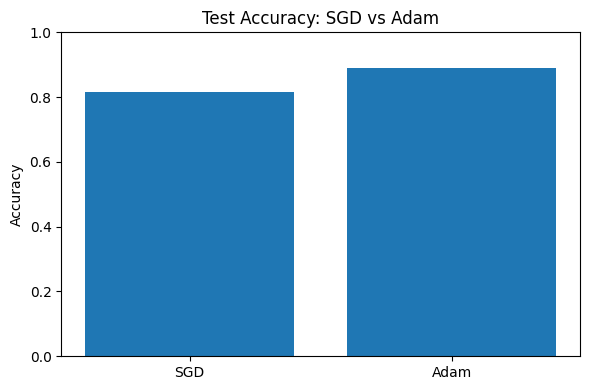

In [15]:

# 10. Compare test accuracy
optimizers = ["SGD", "Adam"]
accuracies = [sgd_accuracy, adam_accuracy]

plt.figure(figsize=(6, 4))
plt.bar(optimizers, accuracies)
plt.title("Test Accuracy: SGD vs Adam")
plt.ylabel("Accuracy")
plt.ylim(0, 1)
plt.tight_layout()
plt.show()
